# Olist E-commerce — Exploration des données

## Étape 2 — Data Exploration & Data Quality

Objectif : comprendre la structure, la qualité et les relations entre les datasets Olist avant de concevoir le Data Warehouse.

**Aucune donnée source ne sera modifiée dans ce notebook.**


## 1. Importation

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")


## 2. Chemin vers les données

In [2]:
RAW_DIR = Path("../data/raw")

if not RAW_DIR.exists():
    raise FileNotFoundError(
        f"Le dossier {RAW_DIR.resolve()} n'existe pas. "
        "Vérifiez que le notebook se trouve dans notebooks/."
    )


## 3. Chargement des datasets

In [3]:
files = {
    "orders": "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "order_payments": "olist_order_payments_dataset.csv",
    "order_reviews": "olist_order_reviews_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "category_translation": "product_category_name_translation.csv",
}

datasets = {
    name: pd.read_csv(RAW_DIR / filename)
    for name, filename in files.items()
}

for name, df in datasets.items():
    print(f"{name:22} -> {len(df):>10,} lignes x {df.shape[1]:>2} colonnes")

orders = datasets["orders"]
order_items = datasets["order_items"]
order_payments = datasets["order_payments"]
order_reviews = datasets["order_reviews"]
customers = datasets["customers"]
products = datasets["products"]
sellers = datasets["sellers"]
geolocation = datasets["geolocation"]
category_translation = datasets["category_translation"]


orders                 ->     99,441 lignes x  8 colonnes
order_items            ->    112,650 lignes x  7 colonnes
order_payments         ->    103,886 lignes x  5 colonnes
order_reviews          ->     99,224 lignes x  7 colonnes
customers              ->     99,441 lignes x  5 colonnes
products               ->     32,951 lignes x  9 colonnes
sellers                ->      3,095 lignes x  4 colonnes
geolocation            ->  1,000,163 lignes x  5 colonnes
category_translation   ->         71 lignes x  2 colonnes


## 4. Vue d'ensemble

In [4]:
dataset_summary = pd.DataFrame({
    "dataset": list(datasets.keys()),
    "rows": [df.shape[0] for df in datasets.values()],
    "columns": [df.shape[1] for df in datasets.values()],
    "duplicate_rows": [df.duplicated().sum() for df in datasets.values()],
    "null_cells": [df.isna().sum().sum() for df in datasets.values()],
})

dataset_summary


,dataset,rows,columns,duplicate_rows,null_cells
0,orders,99441,8,0,4908
1,order_items,112650,7,0,0
2,order_payments,103886,5,0,0
3,order_reviews,99224,7,0,145903
4,customers,99441,5,0,0
5,products,32951,9,0,2448
6,sellers,3095,4,0,0
7,geolocation,1000163,5,261831,0
8,category_translation,71,2,0,0


## 5. Structure des tables

In [5]:
for name, df in datasets.items():
    print("=" * 80)
    print(name.upper())
    print("=" * 80)
    display(df.head(3))
    display(df.dtypes.to_frame("dtype"))


ORDERS


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00


,dtype
order_id,str
customer_id,str
order_status,str
order_purchase_timestamp,str
order_approved_at,str
order_delivered_carrier_date,str
order_delivered_customer_date,str
order_estimated_delivery_date,str


ORDER_ITEMS


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87


...

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.55,-46.64,sao paulo,SP
1,1046,-23.55,-46.64,sao paulo,SP
2,1046,-23.55,-46.64,sao paulo,SP


,dtype
geolocation_zip_code_prefix,int64
geolocation_lat,float64
geolocation_lng,float64
geolocation_city,str
geolocation_state,str


CATEGORY_TRANSLATION


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto


,dtype
product_category_name,str
product_category_name_english,str


## 6. Fonction de contrôle de qualité

In [6]:
def quality_report(df):
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "null_count": df.isna().sum(),
        "null_pct": df.isna().mean().mul(100).round(2),
        "unique_values": df.nunique(dropna=True),
    }).sort_values("null_pct", ascending=False)


## 7. Valeurs manquantes

In [7]:
null_summary = pd.DataFrame([
    {
        "dataset": name,
        "null_cells": int(df.isna().sum().sum()),
        "null_pct_of_cells": round(df.isna().mean().mean() * 100, 2),
    }
    for name, df in datasets.items()
]).sort_values("null_pct_of_cells", ascending=False)

null_summary


,dataset,null_cells,null_pct_of_cells
3,order_reviews,145903,21.01
5,products,2448,0.83
0,orders,4908,0.62
2,order_payments,0,0.00
1,order_items,0,0.00
4,customers,0,0.00
6,sellers,0,0.00
7,geolocation,0,0.00
8,category_translation,0,0.00


In [8]:
for name, df in datasets.items():
    print(f"\n{'=' * 80}\n{name.upper()}\n{'=' * 80}")
    display(quality_report(df))



ORDERS


,dtype,null_count,null_pct,unique_values
order_delivered_customer_date,str,2965,2.98,95664
order_delivered_carrier_date,str,1783,1.79,81018
order_approved_at,str,160,0.16,90733
order_id,str,0,0.00,99441
order_purchase_timestamp,str,0,0.00,98875
order_status,str,0,0.00,8
customer_id,str,0,0.00,99441
order_estimated_delivery_date,str,0,0.00,459



ORDER_ITEMS


,dtype,null_count,null_pct,unique_values
order_id,str,0,0.00,98666
order_item_id,int64,0,0.00,21
product_id,str,0,0.00,32951
seller_id,str,0,0.00,3095
shipping_limit_date,str,0,0.00,93318
price,float64,0,0.00,5968
freight_value,float64,0,0.00,6999



ORDER_PAYMENTS


...

,dtype,null_count,null_pct,unique_values
seller_id,str,0,0.00,3095
seller_zip_code_prefix,int64,0,0.00,2246
seller_city,str,0,0.00,611
seller_state,str,0,0.00,23



GEOLOCATION


,dtype,null_count,null_pct,unique_values
geolocation_zip_code_prefix,int64,0,0.00,19015
geolocation_lat,float64,0,0.00,717360
geolocation_lng,float64,0,0.00,717613
geolocation_city,str,0,0.00,8011
geolocation_state,str,0,0.00,27



CATEGORY_TRANSLATION


,dtype,null_count,null_pct,unique_values
product_category_name,str,0,0.00,71
product_category_name_english,str,0,0.00,71


## 8. Doublons

In [9]:
duplicate_summary = pd.DataFrame({
    "dataset": list(datasets.keys()),
    "duplicate_rows": [int(df.duplicated().sum()) for df in datasets.values()],
})

duplicate_summary


,dataset,duplicate_rows
0,orders,0
1,order_items,0
2,order_payments,0
3,order_reviews,0
4,customers,0
5,products,0
6,sellers,0
7,geolocation,261831
8,category_translation,0


## 9. Analyse des identifiants

In [10]:
for name in ["orders", "customers", "products", "sellers"]:
    df = datasets[name]
    print(f"\n{name.upper()}")
    display(pd.DataFrame({
        "column": df.columns,
        "unique_values": [df[col].nunique(dropna=True) for col in df.columns],
        "null_values": [df[col].isna().sum() for col in df.columns],
    }))



ORDERS


,column,unique_values,null_values
0,order_id,99441,0
1,customer_id,99441,0
2,order_status,8,0
3,order_purchase_timestamp,98875,0
4,order_approved_at,90733,160
5,order_delivered_carrier_date,81018,1783
6,order_delivered_customer_date,95664,2965
7,order_estimated_delivery_date,459,0



CUSTOMERS


,column,unique_values,null_values
0,customer_id,99441,0
1,customer_unique_id,96096,0
2,customer_zip_code_prefix,14994,0
3,customer_city,4119,0
4,customer_state,27,0



PRODUCTS


,column,unique_values,null_values
0,product_id,32951,0
1,product_category_name,73,610
2,product_name_lenght,66,610
3,product_description_lenght,2960,610
4,product_photos_qty,19,610
5,product_weight_g,2204,2
6,product_length_cm,99,2
7,product_height_cm,102,2
8,product_width_cm,95,2



SELLERS


,column,unique_values,null_values
0,seller_id,3095,0
1,seller_zip_code_prefix,2246,0
2,seller_city,611,0
3,seller_state,23,0


## 10. `customer_id` vs `customer_unique_id`

In [11]:
customer_mapping = customers.groupby("customer_unique_id")["customer_id"].nunique()

print(f"customer_id uniques        : {customers['customer_id'].nunique():,}")
print(f"customer_unique_id uniques : {customers['customer_unique_id'].nunique():,}")
print(f"customer_unique_id associés à plusieurs customer_id : {(customer_mapping > 1).sum():,}")

display(customer_mapping.value_counts().sort_index().to_frame("nombre_de_customer_id"))


customer_id uniques        : 99,441
customer_unique_id uniques : 96,096
customer_unique_id associés à plusieurs customer_id : 2,997


,nombre_de_customer_id
customer_id,
1,93099
2,2745
3,203
4,30
5,8
6,6
7,3
9,1
17,1


## 11. Analyse des commandes

In [12]:
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"], errors="coerce"
)

date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

for col in date_columns[1:]:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

display(orders["order_status"].value_counts(dropna=False).to_frame("count"))
print("Première commande :", orders["order_purchase_timestamp"].min())
print("Dernière commande :", orders["order_purchase_timestamp"].max())


,count
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


Première commande : 2016-09-04 21:15:19
Dernière commande : 2018-10-17 17:30:18


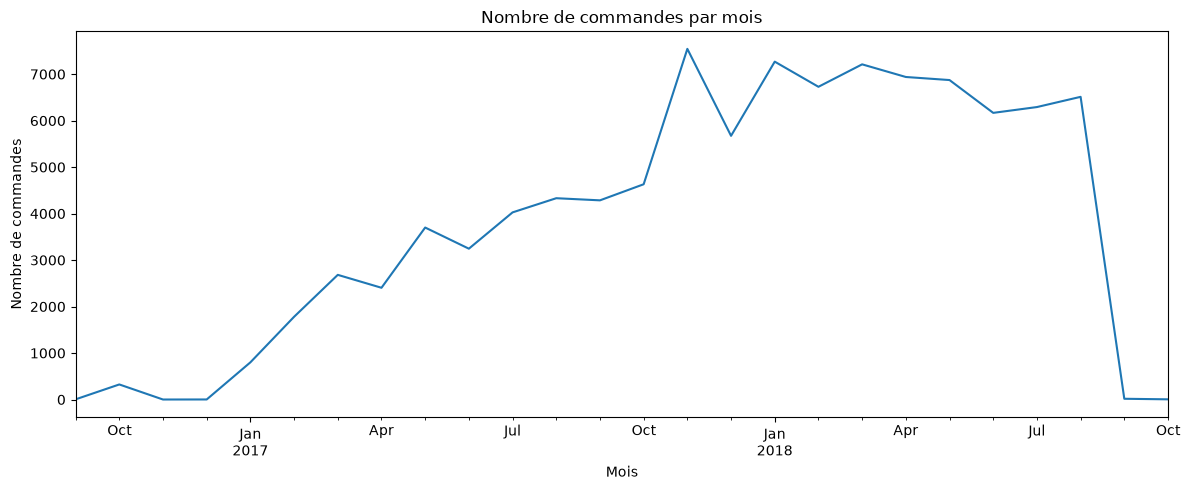

In [13]:
monthly_orders = orders.set_index("order_purchase_timestamp").resample("MS").size()

ax = monthly_orders.plot(figsize=(12, 5))
ax.set_title("Nombre de commandes par mois")
ax.set_xlabel("Mois")
ax.set_ylabel("Nombre de commandes")
plt.tight_layout()
plt.show()


## 12. Analyse des lignes de commande

In [14]:
print(f"Lignes de commande : {len(order_items):,}")
print(f"Commandes distinctes : {order_items['order_id'].nunique():,}")
print(f"Produits distincts : {order_items['product_id'].nunique():,}")
print(f"Vendeurs distincts : {order_items['seller_id'].nunique():,}")

display(order_items[["price", "freight_value"]].describe())


Lignes de commande : 112,650
Commandes distinctes : 98,666
Produits distincts : 32,951
Vendeurs distincts : 3,095


,price,freight_value
count,"112,650.00","112,650.00"
mean,120.65,19.99
std,183.63,15.81
min,0.85,0.00
25%,39.90,13.08
50%,74.99,16.26
75%,134.90,21.15
max,"6,735.00",409.68


In [15]:
items_per_order = order_items.groupby("order_id").size()
display(items_per_order.describe())
print("Commandes avec plusieurs lignes :", int((items_per_order > 1).sum()))


count   98,666.00
mean         1.14
std          0.54
min          1.00
25%          1.00
50%          1.00
75%          1.00
max         21.00
dtype: float64

Commandes avec plusieurs lignes : 9803


## 13. Analyse des paiements

In [16]:
display(order_payments["payment_type"].value_counts(dropna=False).to_frame("count"))
display(order_payments[["payment_value", "payment_installments"]].describe())


,count
payment_type,
credit_card,76795
boleto,19784
voucher,5775
debit_card,1529
not_defined,3


,payment_value,payment_installments
count,"103,886.00","103,886.00"
mean,154.10,2.85
std,217.49,2.69
min,0.00,0.00
25%,56.79,1.00
50%,100.00,1.00
75%,171.84,4.00
max,"13,664.08",24.00


## 14. Analyse des avis clients

,count
review_score,
1,11424
2,3151
3,8179
4,19142
5,57328


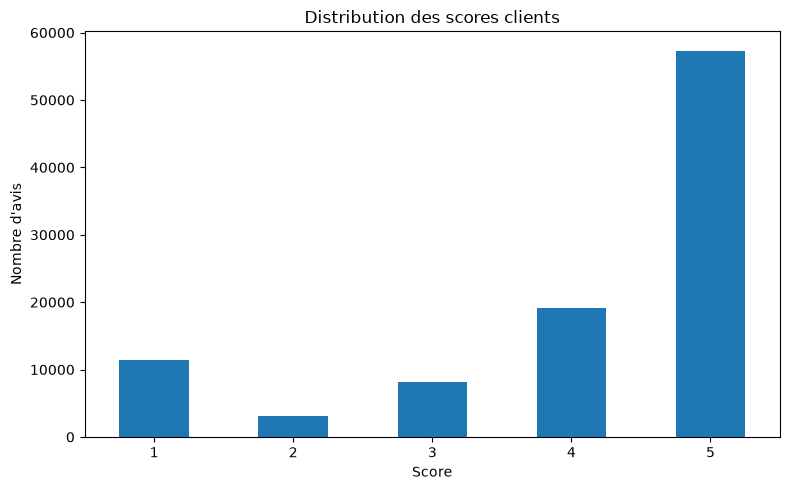

In [17]:
display(order_reviews["review_score"].value_counts(dropna=False).sort_index().to_frame("count"))

review_counts = order_reviews["review_score"].value_counts().sort_index()
ax = review_counts.plot(kind="bar", figsize=(8, 5))
ax.set_title("Distribution des scores clients")
ax.set_xlabel("Score")
ax.set_ylabel("Nombre d'avis")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 15. Analyse des produits

In [18]:
display(quality_report(products))


,dtype,null_count,null_pct,unique_values
product_category_name,str,610,1.85,73
product_description_lenght,float64,610,1.85,2960
product_name_lenght,float64,610,1.85,66
product_photos_qty,float64,610,1.85,19
product_weight_g,float64,2,0.01,2204
product_height_cm,float64,2,0.01,102
product_length_cm,float64,2,0.01,99
product_width_cm,float64,2,0.01,95
product_id,str,0,0.00,32951


,products
product_category_name,
cama_mesa_banho,3029
esporte_lazer,2867
moveis_decoracao,2657
beleza_saude,2444
utilidades_domesticas,2335
automotivo,1900
informatica_acessorios,1639
brinquedos,1411
relogios_presentes,1329


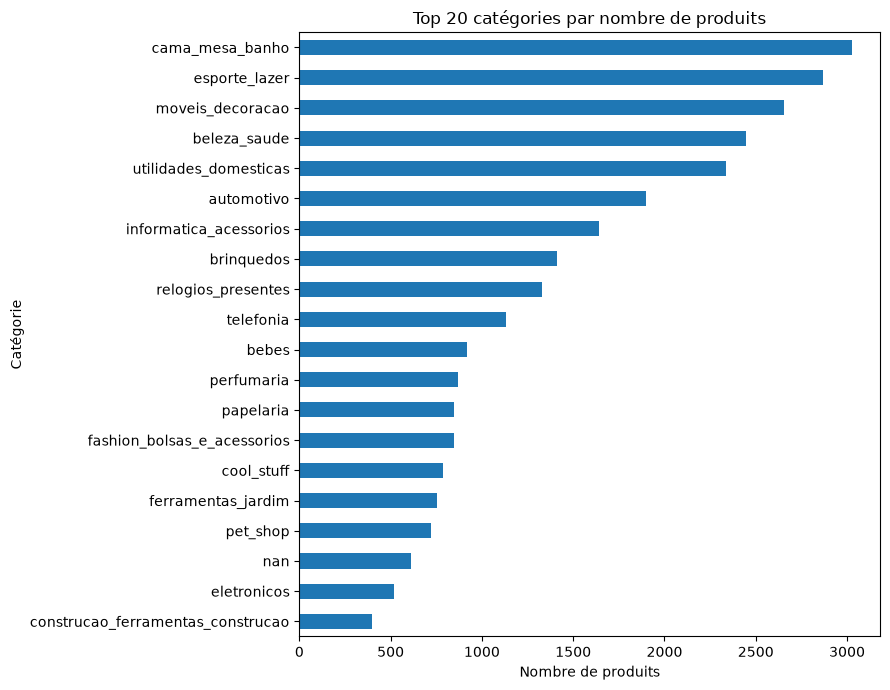

In [19]:
category_counts = products["product_category_name"].value_counts(dropna=False).head(20)
display(category_counts.to_frame("products"))

ax = category_counts.sort_values().plot(kind="barh", figsize=(9, 7))
ax.set_title("Top 20 catégories par nombre de produits")
ax.set_xlabel("Nombre de produits")
ax.set_ylabel("Catégorie")
plt.tight_layout()
plt.show()


## 16. Analyse des vendeurs

In [20]:
print(f"Nombre de vendeurs : {sellers['seller_id'].nunique():,}")
print(f"Nombre d'états : {sellers['seller_state'].nunique():,}")
display(sellers["seller_state"].value_counts().to_frame("count"))


Nombre de vendeurs : 3,095
Nombre d'états : 23


,count
seller_state,
SP,1849
PR,349
MG,244
SC,190
RJ,171
RS,129
GO,40
DF,30
ES,23


## 17. Analyse géographique

In [21]:
print(f"Codes postaux distincts : {geolocation['geolocation_zip_code_prefix'].nunique():,}")
print(f"Villes distinctes        : {geolocation['geolocation_city'].nunique():,}")
print(f"États distincts          : {geolocation['geolocation_state'].nunique():,}")
display(quality_report(geolocation))


Codes postaux distincts : 19,015
Villes distinctes        : 8,011
États distincts          : 27


,dtype,null_count,null_pct,unique_values
geolocation_zip_code_prefix,int64,0,0.00,19015
geolocation_lat,float64,0,0.00,717360
geolocation_lng,float64,0,0.00,717613
geolocation_city,str,0,0.00,8011
geolocation_state,str,0,0.00,27


## 18. Vérification des relations

In [22]:
relationship_checks = {
    "orders.customer_id -> customers.customer_id":
        (~orders["customer_id"].isin(customers["customer_id"])).sum(),
    "order_items.order_id -> orders.order_id":
        (~order_items["order_id"].isin(orders["order_id"])).sum(),
    "order_items.product_id -> products.product_id":
        (~order_items["product_id"].isin(products["product_id"])).sum(),
    "order_items.seller_id -> sellers.seller_id":
        (~order_items["seller_id"].isin(sellers["seller_id"])).sum(),
    "order_payments.order_id -> orders.order_id":
        (~order_payments["order_id"].isin(orders["order_id"])).sum(),
    "order_reviews.order_id -> orders.order_id":
        (~order_reviews["order_id"].isin(orders["order_id"])).sum(),
}

pd.Series(relationship_checks, name="orphan_rows").to_frame()


,orphan_rows
orders.customer_id -> customers.customer_id,0
order_items.order_id -> orders.order_id,0
order_items.product_id -> products.product_id,0
order_items.seller_id -> sellers.seller_id,0
order_payments.order_id -> orders.order_id,0
order_reviews.order_id -> orders.order_id,0


## 19. Cardinalité des relations

In [23]:
cardinality = pd.DataFrame({
    "order_items_per_order": order_items.groupby("order_id").size(),
    "payments_per_order": order_payments.groupby("order_id").size(),
    "reviews_per_order": order_reviews.groupby("order_id").size(),
})

display(cardinality.describe())


,order_items_per_order,payments_per_order,reviews_per_order
count,"98,666.00","99,440.00","98,673.00"
mean,1.14,1.04,1.01
std,0.54,0.38,0.08
min,1.00,1.00,1.00
25%,1.00,1.00,1.00
50%,1.00,1.00,1.00
75%,1.00,1.00,1.00
max,21.00,29.00,3.00


## 20. Cohérence temporelle

In [24]:
temporal_checks = {
    "delivered_before_purchase":
        (orders["order_delivered_customer_date"] < orders["order_purchase_timestamp"]).sum(),
    "carrier_before_purchase":
        (orders["order_delivered_carrier_date"] < orders["order_purchase_timestamp"]).sum(),
    "delivered_after_estimated":
        (orders["order_delivered_customer_date"] > orders["order_estimated_delivery_date"]).sum(),
}

pd.Series(temporal_checks, name="rows").to_frame()


,rows
delivered_before_purchase,0
carrier_before_purchase,166
delivered_after_estimated,7827


## 21. Premiers indicateurs commerciaux

In [25]:
sales = order_items.copy()
sales["total_item_value"] = sales["price"] + sales["freight_value"]

print(f"Valeur produits : {sales['price'].sum():,.2f}")
print(f"Frais de livraison : {sales['freight_value'].sum():,.2f}")
print(f"Valeur totale : {sales['total_item_value'].sum():,.2f}")
print(f"Commandes : {sales['order_id'].nunique():,}")
print(f"Panier moyen simplifié : {sales.groupby('order_id')['total_item_value'].sum().mean():,.2f}")


Valeur produits : 13,591,643.70
Frais de livraison : 2,251,909.54
Valeur totale : 15,843,553.24
Commandes : 98,666
Panier moyen simplifié : 160.58


## 22. Synthèse des observations

### Structure

L'analyse met en évidence plusieurs types de tables avec des grains différents.

#### Tables transactionnelles

- `orders` : une ligne correspond à une commande (`order_id`). La table contient 99 441 commandes.
- `order_items` : une ligne correspond à un article d'une commande. Une commande peut contenir plusieurs lignes, avec jusqu'à 21 articles différents. Le grain est donc lié au couple `order_id` / `order_item_id`.
- `order_payments` : une commande peut être associée à plusieurs paiements. La table contient jusqu'à 29 enregistrements de paiement pour une même commande.
- `order_reviews` : une commande peut être associée à plusieurs avis dans les données, avec jusqu'à 3 enregistrements pour une même commande.

Ces tables ne doivent donc pas être considérées comme ayant le même grain.

#### Tables de référence / dimensions potentielles

- `customers` : une ligne par `customer_id`. Cependant, plusieurs `customer_id` peuvent correspondre au même `customer_unique_id`. 96 096 clients uniques sont associés à 99 441 `customer_id`, et 2 997 `customer_unique_id` sont associés à plusieurs `customer_id`.
- `products` : une ligne par `product_id`, soit 32 951 produits.
- `sellers` : une ligne par `seller_id`, soit 3 095 vendeurs.
- `product_category_name_translation` : table de référence permettant de traduire les catégories de produits.
- `geolocation` : table de référence géographique contenant plusieurs enregistrements pour un même code postal. Elle contient 19 015 codes postaux distincts et présente un nombre important de doublons exacts.

#### Grain à retenir

Le grain principal envisagé pour l'analyse commerciale sera probablement celui de `order_items`, c'est-à-dire **une ligne de produit vendue dans une commande**.

Cependant, les paiements et les avis possèdent des grains différents. Ils devront probablement être modélisés séparément ou agrégés avant d'être associés à une fact table afin d'éviter de multiplier artificiellement les montants lors des jointures.

---

### Data Quality

Plusieurs problèmes de qualité ont été identifiés.

#### Valeurs manquantes

La table `orders` contient principalement des valeurs manquantes dans les dates liées au traitement et à la livraison :

- `order_delivered_customer_date` : 2 965 valeurs manquantes (2,98 %) ;
- `order_delivered_carrier_date` : 1 783 valeurs manquantes (1,79 %) ;
- `order_approved_at` : 160 valeurs manquantes (0,16 %).

Ces valeurs peuvent notamment être liées aux commandes qui n'ont pas été livrées et ne doivent donc pas être automatiquement remplacées.

La table `order_reviews` contient également beaucoup de valeurs manquantes :

- `review_comment_title` : 87 656 valeurs manquantes (88,34 %) ;
- `review_comment_message` : 58 247 valeurs manquantes (58,70 %).

Ces valeurs ne constituent pas nécessairement une anomalie : les commentaires sont optionnels pour un avis.

La table `products` présente également des valeurs manquantes :

- 610 produits sans catégorie ;
- 610 valeurs manquantes pour plusieurs variables descriptives ;
- 2 valeurs manquantes pour les dimensions physiques et le poids.

#### Doublons

Aucun doublon exact n'a été identifié dans les principales tables transactionnelles ou de référence, à l'exception de `geolocation`.

La table `geolocation` contient **261 831 doublons exacts**. Cette table devra donc être étudiée et probablement dédupliquée ou agrégée avant son intégration au Data Warehouse.

#### Autres problèmes identifiés

L'analyse temporelle révèle :

- 0 commande avec une livraison client antérieure à la date d'achat ;
- 166 enregistrements où la livraison au transporteur précède la date d'achat ;
- 7 827 commandes livrées après la date estimée.

Les 166 cas précédant la date d'achat devront être examinés plus précisément afin de déterminer s'il s'agit d'anomalies de données ou de cas particuliers.

Les 7 827 livraisons après la date estimée constituent en revanche une information métier intéressante qui pourra être utilisée pour calculer un indicateur de retard de livraison.

---

### Relations

Les principales relations entre les tables sont cohérentes : aucun enregistrement orphelin n'a été détecté pour les relations testées.

Les relations suivantes peuvent donc être considérées comme valides :

- `orders.customer_id` → `customers.customer_id`
- `order_items.order_id` → `orders.order_id`
- `order_items.product_id` → `products.product_id`
- `order_items.seller_id` → `sellers.seller_id`
- `order_payments.order_id` → `orders.order_id`
- `order_reviews.order_id` → `orders.order_id`

Cependant, ces relations ne présentent pas toutes la même cardinalité.

- `customers` → `orders` : un client peut avoir plusieurs commandes.
- `orders` → `order_items` : une commande peut contenir plusieurs lignes de commande.
- `orders` → `order_payments` : une commande peut avoir plusieurs paiements.
- `orders` → `order_reviews` : une commande peut avoir plusieurs reviews dans les données.
- `products` → `order_items` : un produit peut apparaître dans plusieurs lignes de commande.
- `sellers` → `order_items` : un vendeur peut être associé à plusieurs lignes de commande.

Une attention particulière devra donc être portée aux jointures entre les tables transactionnelles afin d'éviter les duplications de mesures.

---

### Cas particuliers à prendre en compte

Le couple `customer_id` / `customer_unique_id` constitue un point important pour la modélisation.

`customer_id` est unique dans la table `customers`, alors que `customer_unique_id` représente un niveau d'identification différent : 2 997 `customer_unique_id` sont associés à plusieurs `customer_id`.

Il faudra donc déterminer lors de la modélisation quel identifiant représente le mieux le niveau « client » recherché pour les analyses.

La table `geolocation` constitue également un cas particulier en raison de son volume important et de ses 261 831 doublons exacts. Elle ne devra pas être intégrée directement au modèle sans transformation préalable.

Enfin, `order_items`, `order_payments` et `order_reviews` ont des grains différents. Les mesures provenant de ces tables ne devront pas être combinées directement sans agrégation préalable.

---

### Conclusions pour la modélisation

L'exploration suggère que le futur Data Warehouse devra probablement s'appuyer sur plusieurs niveaux de faits plutôt que sur une seule table transactionnelle regroupant toutes les informations.

La table `order_items` constitue une candidate naturelle pour une **fact table principale des ventes**, avec un grain correspondant à une ligne de commande.

Les informations de paiement et de satisfaction devront être étudiées séparément afin de déterminer s'il est préférable de créer des tables de faits dédiées ou de construire des agrégations au niveau de la commande.

Les dimensions potentielles comprennent notamment :

- `dim_customer`
- `dim_product`
- `dim_seller`
- `dim_date`
- éventuellement une dimension géographique.

Ces choix seront définis précisément lors de l'étape suivante.

---

### Prochaine étape

Les résultats de cette exploration serviront à construire le **Data Dictionary** et le **Star Schema** de l'étape 3.

L'étape suivante consistera donc à :

1. définir précisément le grain de chaque future table de faits ;
2. identifier les dimensions nécessaires ;
3. définir les clés primaires et étrangères ;
4. déterminer les mesures et indicateurs à conserver ;
5. décider comment traiter `customer_id` et `customer_unique_id` ;
6. définir le traitement de la table `geolocation` ;
7. déterminer comment intégrer les paiements et les avis sans créer de duplication des mesures ;
8. construire le modèle en étoile destiné à alimenter les analyses Tableau.